# 01 — Data: download, alignment, features, split

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 1 (data only, no modelling).

| | |
|---|---|
| **Input** | Yahoo Finance via `yfinance` (downloaded once into `data/raw/`) |
| **Output** | `data/processed/panel.csv` + `panel.parquet`, `figures/fig_01_*.png`, split dates in `config.yaml` |
| **Brief** | §1.1 (data, ≥1 derived indicator), §1.3 (native time-series object, 90/10 chronological split, provider adjustments) |

Every later notebook (Python and R) reads **only** `data/processed/panel.*`.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config, data, plotting

SEED = config.set_seed()   # fixed seed (42) for reproducibility, even though this phase has no randomness
cfg = config.load_config()
pd.set_option("display.width", 160, "display.max_columns", 30)
print("root:", ROOT.name, "| seed:", SEED, "| pandas", pd.__version__)

root: Bitcoin miners | seed: 42 | pandas 3.1.1


## 1. Download (once)

* One CSV per ticker in `data/raw/`, columns `Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits`.
* `auto_adjust=False`: Yahoo's `Close` is adjusted for **splits only**; `Adj Close` is adjusted for **splits and dividends**. We keep both so the provider adjustment is visible, and every analysis uses `Adj Close`.
* The download starts on `download_start` (2021-01-01), before the study window, so the raw files also show the pre-merger shell periods discussed below.
* If the files already exist they are **not** downloaded again (Yahoo revises history; re-downloading would silently change the data). Set `FORCE_DOWNLOAD = True` only to refresh deliberately.

In [2]:
# Download only when raw files are missing, so re-running the notebook never changes the data.
FORCE_DOWNLOAD = False
status = data.download_raw(force=FORCE_DOWNLOAD)
print(status.to_string(index=False))
print(open(config.path("raw") / "_download_log.json").read())

 ticker     file status
   IREN IREN.csv cached
   CIFR CIFR.csv cached
   WULF WULF.csv cached
   MARA MARA.csv cached
   CLSK CLSK.csv cached
   RIOT RIOT.csv cached
BTC-USD  BTC.csv cached
   NVDA NVDA.csv cached
{
  "IREN": {
    "file": "IREN.csv",
    "downloaded_utc": "2026-11-09 19:36:08",
    "yfinance": "1.8.0",
    "rows": 1243,
    "first": "2021-11-17",
    "last": "2026-10-30"
  },
  "CIFR": {
    "file": "CIFR.csv",
    "downloaded_utc": "2026-11-09 19:36:08",
    "yfinance": "1.8.0",
    "rows": 1464,
    "first": "2021-01-04",
    "last": "2026-10-30"
  },
  "WULF": {
    "file": "WULF.csv",
    "downloaded_utc": "2026-11-09 19:36:09",
    "yfinance": "1.8.0",
    "rows": 1464,
    "first": "2021-01-04",
    "last": "2026-10-30"
  },
  "MARA": {
    "file": "MARA.csv",
    "downloaded_utc": "2026-11-09 19:36:09",
    "yfinance": "1.8.0",
    "rows": 1464,
    "first": "2021-01-04",
    "last": "2026-10-30"
  },
  "CLSK": {
    "file": "CLSK.csv",
    "downloaded_utc": 

## 2. Raw data overview and the shell-company issue

`yfinance` returns history for WULF back to 1994 and for CIFR back to 2020, but those rows belong to **other companies**:

* **WULF**: IKONICS Corp. until the reverse merger with TeraWulf closed on 13 Dec 2021; the first TeraWulf session is **2021-12-14** (volume jumps ≈7×, see below).
* **CIFR**: Good Works Acquisition Corp. (a SPAC trading near $10) until the merger with Cipher Mining at the end of Aug 2021.
* **IREN**: IPO on 2021-11-17, no earlier history.

Those prices carry no information about a Bitcoin miner, so the common study window starts on **2021-12-14** (WULF) and ends on the frozen date **2026-10-31**.
That is **4.88 years**, slightly below the brief's "≥ 5 years". Justification: the phenomenon studied (miners pivoting to AI) only exists for companies listed from 2021, the two
most representative converts (IREN, WULF) cannot have a longer history, and ~1,230 daily observations is ample for every method of the brief.

Provider adjustments visible in the table below: **NVDA** 10-for-1 split (2024-06-10) and quarterly dividends, both absorbed in `Adj Close`; **WULF** shows a $5.00 "dividend" on 2021-12-14,
which is the cash distribution paid to IKONICS shareholders at the merger. Yahoo applies it only to prices *before* 2021-12-14, i.e. outside the window, so the panel is unaffected.

In [3]:
# Read back from disk (never from the API) and check coverage + data quality inside the window.
raw = data.load_raw()
data.raw_overview(raw)

,raw_first,raw_last,raw_rows,window_rows,duplicate_dates,nan_adj_close,non_positive_price,zero_volume_days,dividend_events,split_events
asset,,,,,,,,,,
IREN,2021-11-17,2026-10-30,1243,1225,0,0,0,0,0,0
CIFR,2021-01-04,2026-10-30,1464,1225,0,0,0,0,0,0
WULF,2021-01-04,2026-10-30,1464,1225,0,0,0,0,1,0
MARA,2021-01-04,2026-10-30,1464,1225,0,0,0,0,0,0
CLSK,2021-01-04,2026-10-30,1464,1225,0,0,0,1,0,0
RIOT,2021-01-04,2026-10-30,1464,1225,0,0,0,0,0,0
BTC,2021-01-01,2026-10-31,2130,1783,0,0,0,0,0,0
NVDA,2021-01-04,2026-10-30,1464,1225,0,0,0,0,19,1


In [4]:
# Evidence for the WULF start date: the merger shows up as a regime change in traded volume.
raw["WULF"].loc["2021-12-07":"2021-12-17", ["Adj Close", "Volume"]]

,Adj Close,Volume
Date,,
2021-12-07,28.098642,28900
2021-12-08,29.198378,38500
2021-12-09,29.488230,28100
2021-12-10,28.985250,48700
2021-12-13,28.900000,55100
2021-12-14,20.299999,353100
2021-12-15,19.520000,200200
2021-12-16,16.230000,234400
2021-12-17,12.950000,248500


## 3. Alignment on the stock trading calendar

**Rule:** keep US stock trading days only (union of the 7 stocks' dates inside the window); BTC-USD is sampled on those days.

* Why: BTC trades 7 days a week, stocks 5. Joint models (VAR, VECM, Granger, cointegration) need observations taken **at the same time**; filling stock prices on weekends would create fake zero returns.
* Consequence: a Monday BTC log return covers Friday → Monday (3 calendar days). Documented in `DATA_DICTIONARY.md`.
* **Provider placeholder rows** (volume = 0 and High = Low, i.e. Yahoo repeating the previous close for a session it did not record) are treated as missing. Found: CLSK on 2024-11-08 (CLSK actually traded that day).
* Missing values on a trading day are forward-filled for prices (return = 0 that day, the move is booked on the next real session), volume set to 0, and every case is counted and dated below.

In [5]:
# Align every asset on the same dates and report exactly what had to be filled.
prices, missing = data.align_prices(raw)
holidays = data.market_holidays(prices.index)
print(f"Trading days: {len(prices)}  ({prices.index.min().date()} -> {prices.index.max().date()})")
print(f"Weekdays without trading (exchange holidays / closures): {len(holidays)}")
missing

Trading days: 1225  (2021-12-14 -> 2026-10-30)
Weekdays without trading (exchange holidays / closures): 49


,trading_days,stale_rows,missing_before_fill,missing_after_fill,missing_dates
asset,,,,,
IREN,1225,0,0,0,
CIFR,1225,0,0,0,
WULF,1225,0,0,0,
MARA,1225,0,0,0,
CLSK,1225,1,1,0,2024-11-08
RIOT,1225,0,0,0,
BTC,1225,0,0,0,
NVDA,1225,0,0,0,


## 4. Derived indicators (brief §1.1)

For every asset, computed on `Adj Close`:

| feature | definition | why |
|---|---|---|
| `log_price` | ln(Adj Close) | levels used in cointegration (VECM) |
| `log_return` | ln(P_t / P_{t-1}) | stationary-candidate series for ARIMA/GARCH |
| `rv20` | 20-day rolling std of log returns × √252 | realised volatility (annualised) |
| `ma20`, `ma50` | 20/50-day simple moving averages of Adj Close | short/medium trend |

Rolling features are `NaN` during their warm-up (19 rows for `rv20`/`ma20`, 49 for `ma50`); we do **not** borrow pre-window data because the WULF/CIFR pre-window rows are shell companies.

**Group indices.** `CONVERTS` = IREN, CIFR, WULF and `PURE` = MARA, CLSK, RIOT. Index log return = equal-weighted mean of members' log returns; level = 100·exp(cumsum), i.e. 100 on 2021-12-14.
Why: one firm's news (a contract, a dilution, a hack) dominates a single small-cap miner; averaging three firms reduces that idiosyncratic noise so the comparison
**converts vs pure** reflects the business model. The individual tickers stay in the panel for robustness checks.

In [6]:
# Build features and group indices, then declare the trading-day frequency on the DatetimeIndex (brief §1.3).
panel = data.build_features(prices)
panel = data.build_indices(panel)
panel = data.set_trading_freq(panel)
print("shape:", panel.shape, "| index:", type(panel.index).__name__, "| freq:", panel.index.freqstr)
print("index levels on day 1:", panel[["CONVERTS_level", "PURE_level"]].iloc[0].to_dict())
panel.filter(regex="^(CONVERTS|PURE|BTC|NVDA)_(level|adj_close|log_return|rv20)$").tail()

shape: (1225, 100) | index: DatetimeIndex | freq: C
index levels on day 1: {'CONVERTS_level': 100.0, 'PURE_level': 100.0}


,BTC_adj_close,NVDA_adj_close,BTC_log_return,BTC_rv20,NVDA_log_return,NVDA_rv20,CONVERTS_level,CONVERTS_log_return,CONVERTS_rv20,PURE_level,PURE_log_return,PURE_rv20
Date,,,,,,,,,,,,
2026-10-26,80006.65625,216.000000,-0.013255,0.231529,0.023610,0.302628,123.057519,0.016044,0.759342,39.011515,-0.011752,0.598201
2026-10-27,80805.07812,217.940002,0.009930,0.235203,0.008941,0.304987,132.706905,0.075491,0.837972,41.186523,0.054254,0.662409
2026-10-28,81267.58594,215.380005,0.005707,0.236668,-0.011816,0.305600,139.651660,0.051008,0.875643,43.242024,0.048702,0.703457
2026-10-29,77775.10938,213.660004,-0.043926,0.271890,-0.008018,0.301661,129.081445,-0.078708,0.901336,41.539867,-0.040159,0.707246
2026-10-30,77198.21094,204.639999,-0.007445,0.272110,-0.043134,0.324691,117.561736,-0.093480,0.918087,38.934648,-0.064769,0.715309


In [7]:
# NaN count per column: should only be the rolling-window warm-up and the first return, nothing else.
na = panel.isna().sum()
na = na[na > 0]
print("NaN count -> features concerned (same for every asset)")
for n in sorted(na.unique()):
    print(f"{n:>4} -> {sorted({c.split('_', 1)[1] for c in na[na == n].index})}")
print("columns with NaN:", len(na), "of", panel.shape[1])

NaN count -> features concerned (same for every asset)
   1 -> ['log_return']
  19 -> ['ma20']
  20 -> ['rv20']
  49 -> ['ma50']
columns with NaN: 40 of 100


## 5. Save the processed panel

In [8]:
# Save CSV (for R and humans) and Parquet (typed), then reload both to prove they are identical.
files = data.save_panel(panel)
p_parq, p_csv = data.load_panel("parquet"), data.load_panel("csv")
pd.testing.assert_frame_equal(p_parq, p_csv, check_exact=False, rtol=1e-12, check_freq=True)
pd.testing.assert_frame_equal(p_parq, panel, check_exact=False, rtol=1e-12)
print("saved:", [str(f.relative_to(ROOT)) for f in files.values()], "| reload OK, freq:", p_parq.index.freqstr)

saved: ['data\\processed\\panel.csv', 'data\\processed\\panel.parquet'] | reload OK, freq: C


## 6. Chronological 90 / 10 split (brief §1.3)

Split on the row count of the panel: the first 90 % of trading days train, the last 10 % test. No shuffling, ever. The dates are written into `config.yaml` so every notebook (Python and R) uses the same split. No model is fitted here.

In [9]:
# Compute the split once and store it in config.yaml so all later phases share it.
train, test = data.chrono_split(panel)
split = {"n_obs": len(panel), "n_train": len(train), "n_test": len(test),
         "train_start": str(train.index[0].date()), "train_end": str(train.index[-1].date()),
         "test_start": str(test.index[0].date()), "test_end": str(test.index[-1].date())}
config.update_split(split)
assert config.load_config()["split"]["test_start"] == split["test_start"]
pd.Series(split)

n_obs                1225
n_train              1102
n_test                123
train_start    2021-12-14
train_end      2026-05-06
test_start     2026-05-07
test_end       2026-10-30
dtype: object

## 7. Sanity plots (no interpretation yet — that is Phase 2)

figures\fig_01_rebased_prices_by_group.png


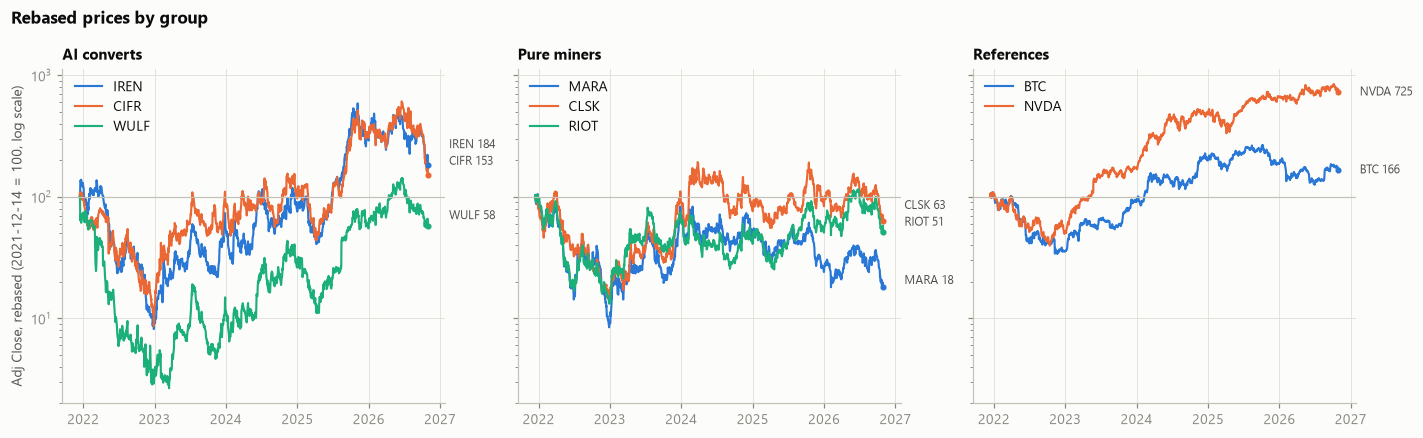

In [10]:
# Rebased prices per group on a log scale: miners move by 10x, a linear axis would hide the small ones.
plotting.set_style()
groups = {"AI converts": ["IREN", "CIFR", "WULF"], "Pure miners": ["MARA", "CLSK", "RIOT"], "References": ["BTC", "NVDA"]}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (title, cols) in zip(axes, groups.items()):
    series = {c: 100 * panel[f"{c}_adj_close"] / panel[f"{c}_adj_close"].iloc[0] for c in cols}
    colors = dict(zip(cols, plotting.SERIES))
    for c, s in series.items():
        ax.plot(s.index, s, color=colors[c], label=c)
    ax.axhline(100, color=plotting.AXIS, lw=0.8)
    ax.set_yscale("log"); ax.set_title(title); ax.legend(loc="upper left")
    plotting.label_line_ends(ax, series, colors)
axes[0].set_ylabel("Adj Close, rebased (2021-12-14 = 100, log scale)")
fig.suptitle("Rebased prices by group", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
print(plotting.save(fig, "fig_01_rebased_prices_by_group"))
plt.show()

figures\fig_01_indices_vs_references.png


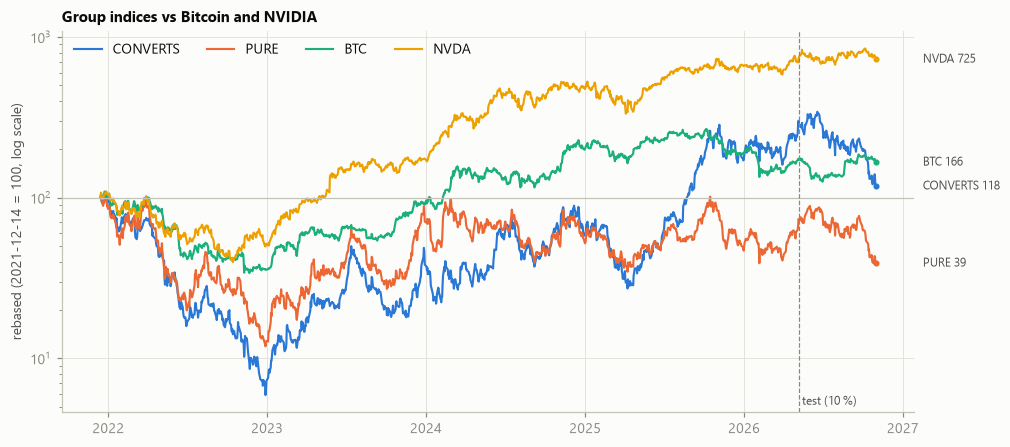

In [11]:
# The four series the core models will use, on one common base (no dual axis).
cols = {"CONVERTS": "CONVERTS_level", "PURE": "PURE_level", "BTC": "BTC_adj_close", "NVDA": "NVDA_adj_close"}
series = {k: 100 * panel[v] / panel[v].iloc[0] for k, v in cols.items()}
colors = dict(zip(cols, plotting.SERIES))
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, s in series.items():
    ax.plot(s.index, s, color=colors[k], label=k)
ax.axhline(100, color=plotting.AXIS, lw=0.8)
ax.axvline(test.index[0], color=plotting.MUTED, lw=0.8, ls="--")
ax.text(test.index[0], 0.02, " test (10 %)", transform=ax.get_xaxis_transform(), fontsize=8, color=plotting.INK2)
ax.set_yscale("log"); ax.set_ylabel("rebased (2021-12-14 = 100, log scale)"); ax.legend(loc="upper left", ncol=4)
ax.set_title("Group indices vs Bitcoin and NVIDIA")
plotting.label_line_ends(ax, series, colors)
print(plotting.save(fig, "fig_01_indices_vs_references"))
plt.show()

## 8. Fingerprint for the R cross-check

In [12]:
# Write summary statistics that notebooks/r/01_data.Rmd recomputes, to prove both languages read identical data.
key_cols = [f"{c}_{f}" for c in ["IREN", "CIFR", "WULF", "MARA", "CLSK", "RIOT", "BTC", "NVDA"] for f in ("adj_close", "log_return")]
key_cols += [f"{c}_{f}" for c in ["CONVERTS", "PURE"] for f in ("level", "log_return")]
fp = data.summary_stats(panel, key_cols)
fp.to_csv(config.path("results") / "01_summary_python.csv", float_format="%.17g")
print(f"n_obs={len(panel)}  n_cols={panel.shape[1]}  first={panel.index[0].date()}  last={panel.index[-1].date()}")
fp.round(4)

n_obs=1225  n_cols=100  first=2021-12-14  last=2026-10-30


,count,mean,std,min,max
column,,,,,
IREN_adj_close,1225.0,16.5509,17.4110,1.0600,76.4100
IREN_log_return,1224.0,0.0005,0.0724,-0.4533,0.5128
CIFR_adj_close,1225.0,6.6354,6.4361,0.4120,29.1800
CIFR_log_return,1224.0,0.0003,0.0757,-0.6302,0.3711
WULF_adj_close,1225.0,6.6855,6.4874,0.5400,28.9800
WULF_log_return,1224.0,-0.0004,0.0774,-0.4300,0.4670
MARA_adj_close,1225.0,14.6847,6.0875,3.1500,39.4000
MARA_log_return,1224.0,-0.0014,0.0649,-0.2132,0.2789
CLSK_adj_close,1225.0,9.4655,4.7466,1.7800,23.4000


## Phase 1 summary

* Window, observation count, split dates: printed above and stored in `config.yaml`.
* Decisions (window start, calendar alignment, fill rule, indices) are documented in `data/DATA_DICTIONARY.md` and `PROGRESS.md`.
* **Next:** Phase 2 — EDA (`02_eda.ipynb`): ACF/PACF, decomposition, outliers, ADF + KPSS.